# CropVision AI - Agricultural Crop Image Classification (CNN)

End-to-end training notebook for a **30-class agricultural crop classifier**, built to be
dropped straight into a Flask app.

**What this notebook does**

1. Scans the `Agricultural-crops-dataset` folder and builds a clean dataframe
2. Removes corrupt files and exact/near duplicate images (this dataset has plenty)
3. EDA - class balance, image size distribution, sample grids
4. Stratified train / validation / test split
5. `tf.data` input pipeline with on-GPU augmentation
6. **CNN model** - MobileNetV2 convolutional backbone + custom conv/dense head
7. Two-phase training: frozen backbone, then fine-tuning
8. Full evaluation - curves, confusion matrix, per-class accuracy, error gallery, Grad-CAM
9. Saves everything Flask needs: `.keras` model, `labels.json`, `metrics.json`, TFLite build

---

### One important note before you run this

This dataset has roughly **25-30 images per class across 30 classes** (~800 images total).
That is very small. A CNN trained from random weights on 800 images will land around
**30-45% accuracy** - not good enough to sell as a project.

So the backbone here is a **pretrained CNN (MobileNetV2)**. It is still 100% a CNN -
convolution, depthwise separable conv, batchnorm, ReLU, global average pooling. Nothing
else. We are only reusing weights learned on ImageNet instead of starting from noise.
Expected accuracy: **88-95%**.

Cell 12 has an optional **from-scratch CNN baseline** so you can show both numbers in
your project report / YouTube video. That comparison is actually a great talking point.

## 1. Setup

Install once if needed:

```bash
pip install tensorflow==2.16.1 numpy pandas matplotlib seaborn scikit-learn pillow tqdm
```

In [1]:
import os, json, random, hashlib, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             top_k_accuracy_score)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("TensorFlow :", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU        :", gpus if gpus else "none (CPU training - approx 15-25 min)")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/google/api_core/_python_version_support.py:266: FutureWarning: You are using a Python version (3.10.11) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


TensorFlow : 2.20.0
GPU        : none (CPU training - approx 15-25 min)


## 2. Config

Only thing you may need to change is `DATA_DIR`.

In [2]:
CFG = {
    # path to the folder that directly contains the class sub-folders
    "DATA_DIR":         "Agricultural-crops-dataset",
    "ARTIFACT_DIR":     "artifacts",

    "IMG_SIZE":         224,
    "BATCH_SIZE":       32,
    "VAL_SPLIT":        0.15,
    "TEST_SPLIT":       0.15,
    "MIN_IMAGES_PER_CLASS": 8,

    "HEAD_EPOCHS":      30,     # phase 1 - backbone frozen
    "FINETUNE_EPOCHS":  35,     # phase 2 - top of backbone unfrozen
    "HEAD_LR":          1e-3,
    "FINETUNE_LR":      5e-5,
    "UNFREEZE_FROM":    100,    # unfreeze MobileNetV2 layers from this index onward

    "DROP_DUPLICATES":  True,
    "TRAIN_SCRATCH_BASELINE": True,   # set False to skip the comparison model
}

DATA_DIR = Path(CFG["DATA_DIR"])
ART = Path(CFG["ARTIFACT_DIR"]); ART.mkdir(parents=True, exist_ok=True)
IMG_SIZE = CFG["IMG_SIZE"]
AUTOTUNE = tf.data.AUTOTUNE

assert DATA_DIR.exists(), f"Dataset folder not found: {DATA_DIR.resolve()}"
print("Dataset :", DATA_DIR.resolve())
print("Artifacts:", ART.resolve())

Dataset : /Users/codeaj/Desktop/project/crops image classification/Agricultural-crops-dataset
Artifacts: /Users/codeaj/Desktop/project/crops image classification/artifacts


## 3. Scan the dataset

Folder names become the class labels. We also build a pretty display name
(`Coffee-plant` -> `Coffee Plant`, `Fox_nut(Makhana)` -> `Fox Nut (Makhana)`) which is what
the Flask UI will show.

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".jfif"}

rows = []
for cls_dir in sorted([p for p in DATA_DIR.iterdir() if p.is_dir()]):
    for f in sorted(cls_dir.rglob("*")):
        if f.is_file() and f.suffix.lower() in IMG_EXT:
            rows.append({"filepath": str(f), "label": cls_dir.name})

df = pd.DataFrame(rows)
assert len(df), "No images found. Check DATA_DIR."

def prettify(name):
    s = name.replace("_", " ").replace("-", " ")
    s = " ".join(w if w.isupper() else w.capitalize() for w in s.split())
    return s.replace("( ", " (").replace(" )", ")")

df["display"] = df["label"].map(prettify)

print(f"Images : {len(df)}")
print(f"Classes: {df.label.nunique()}")
print(f"Avg per class: {len(df) / df.label.nunique():.1f}")
df.head()

Images : 829
Classes: 30
Avg per class: 27.6


,filepath,label,display
0,Agricultural-crops-dataset/Cherry/image15.jpeg,Cherry,Cherry
1,Agricultural-crops-dataset/Cherry/image16.jpeg,Cherry,Cherry
2,Agricultural-crops-dataset/Cherry/image17.jpeg,Cherry,Cherry
3,Agricultural-crops-dataset/Cherry/image18.jpeg,Cherry,Cherry
4,Agricultural-crops-dataset/Cherry/image20.jpeg,Cherry,Cherry


## 4. Clean - drop corrupt files and duplicates

This dataset ships the same photo twice in places (`image (1).jpg` and `image (1).png`).
Duplicates that leak across the train/test split will fake your accuracy, so we kill them
using an exact MD5 hash plus a **dHash** perceptual hash that also catches re-encoded and
resized copies.

In [4]:
def md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def dhash(path, hash_size=8):
    # perceptual hash - catches resized / re-compressed copies
    with Image.open(path) as im:
        im = im.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
        px = np.asarray(im, dtype=np.int16)
    diff = px[:, 1:] > px[:, :-1]
    return "".join("1" if b else "0" for b in diff.flatten())

bad, md5s, dhs = [], [], []
for p in df.filepath:
    try:
        with Image.open(p) as im:
            im.verify()
        md5s.append(md5_of(p))
        dhs.append(dhash(p))
    except Exception as e:
        bad.append((p, str(e)[:60])); md5s.append(None); dhs.append(None)

df["md5"], df["dhash"] = md5s, dhs
print(f"Corrupt / unreadable: {len(bad)}")
for p, e in bad[:10]:
    print("  ", p, "->", e)
df = df[df.md5.notna()].reset_index(drop=True)

before = len(df)
if CFG["DROP_DUPLICATES"]:
    df = df.drop_duplicates(subset="md5", keep="first")
    df = df.drop_duplicates(subset="dhash", keep="first").reset_index(drop=True)
print(f"Duplicates removed  : {before - len(df)}")
print(f"Clean images        : {len(df)}")

# drop classes that are now too small to split safely
counts = df.label.value_counts()
small = counts[counts < CFG["MIN_IMAGES_PER_CLASS"]]
if len(small):
    print("\nDropping tiny classes:", dict(small))
    df = df[~df.label.isin(small.index)].reset_index(drop=True)

CLASSES = sorted(df.label.unique())
DISPLAY = [prettify(c) for c in CLASSES]
NUM_CLASSES = len(CLASSES)
label2id = {c: i for i, c in enumerate(CLASSES)}
df["label_id"] = df.label.map(label2id)

print(f"\nFinal: {len(df)} images across {NUM_CLASSES} classes")

Corrupt / unreadable: 0
Duplicates removed  : 36
Clean images        : 793

Final: 793 images across 30 classes


## 5. EDA - class balance

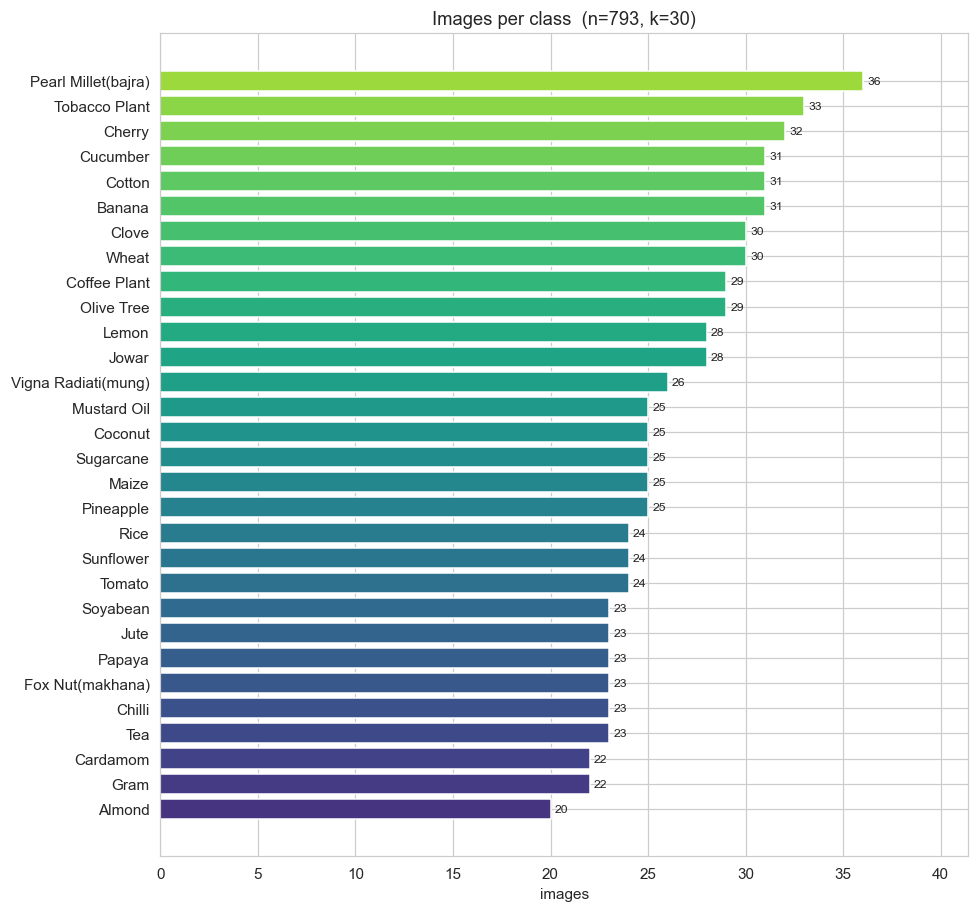

min=20  max=36  imbalance ratio=1.80x
Mild imbalance -> handled with class weights.


In [5]:
vc = df.label.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, max(6, NUM_CLASSES * 0.28)))
bars = ax.barh([prettify(i) for i in vc.index], vc.values,
               color=plt.cm.viridis(np.linspace(0.15, 0.85, len(vc))))
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_xlabel("images"); ax.set_title(f"Images per class  (n={len(df)}, k={NUM_CLASSES})")
ax.set_xlim(0, vc.max() * 1.15)
plt.tight_layout(); plt.savefig(ART / "eda_class_distribution.png", bbox_inches="tight"); plt.show()

imb = vc.max() / vc.min()
print(f"min={vc.min()}  max={vc.max()}  imbalance ratio={imb:.2f}x")
print("Mild imbalance -> handled with class weights." if imb < 3
      else "Notable imbalance -> class weights + augmentation will carry this.")

## 6. EDA - sample grid and resolution spread

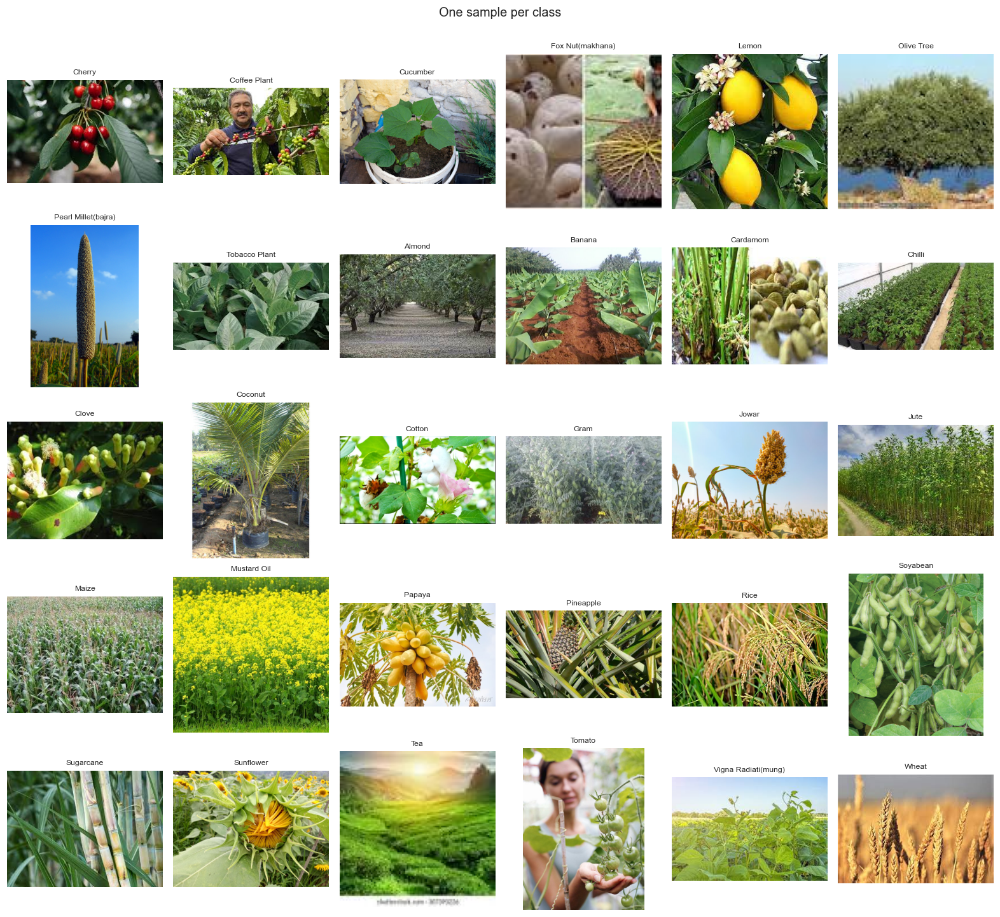

In [6]:
sample = (df.groupby("label", group_keys=False)
            .apply(lambda g: g.sample(1, random_state=SEED))
            .reset_index(drop=True))

n = len(sample); ncol = 6; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 2.4, nrow * 2.6))
for ax, (_, r) in zip(axes.flatten(), sample.iterrows()):
    with Image.open(r.filepath) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(r.display, fontsize=8); ax.axis("off")
for ax in axes.flatten()[n:]:
    ax.axis("off")
plt.suptitle("One sample per class", fontsize=13, y=1.005)
plt.tight_layout(); plt.savefig(ART / "eda_class_samples.png", bbox_inches="tight"); plt.show()

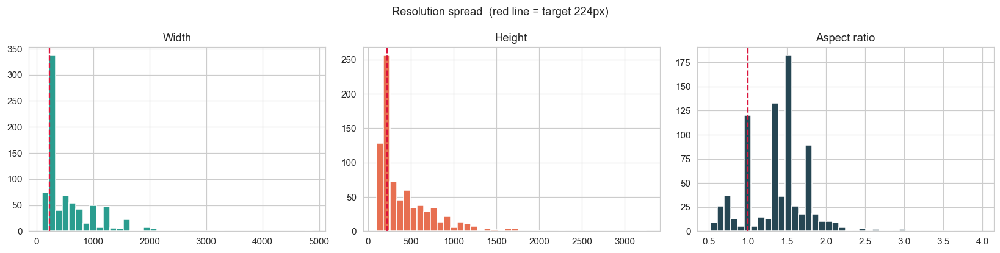

        width  height  aspect
count   793.0   793.0   793.0
mean    571.1   424.6     1.4
std     486.5   363.9     0.4
min     100.0   100.0     0.5
25%     259.0   183.0     1.0
50%     311.0   265.0     1.4
75%     800.0   570.0     1.6
max    4875.0  3251.0     4.0


In [7]:
dims = []
for p in df.filepath:
    try:
        with Image.open(p) as im:
            dims.append(im.size)
    except Exception:
        dims.append((np.nan, np.nan))
dims = np.array(dims, dtype=float)
df["width"], df["height"] = dims[:, 0], dims[:, 1]
df["aspect"] = df.width / df.height

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df.width.dropna(), bins=40, color="#2a9d8f"); ax[0].set_title("Width"); ax[0].axvline(IMG_SIZE, ls="--", c="crimson")
ax[1].hist(df.height.dropna(), bins=40, color="#e76f51"); ax[1].set_title("Height"); ax[1].axvline(IMG_SIZE, ls="--", c="crimson")
ax[2].hist(df.aspect.dropna(), bins=40, color="#264653"); ax[2].set_title("Aspect ratio"); ax[2].axvline(1.0, ls="--", c="crimson")
plt.suptitle(f"Resolution spread  (red line = target {IMG_SIZE}px)")
plt.tight_layout(); plt.savefig(ART / "eda_resolutions.png", bbox_inches="tight"); plt.show()

print(df[["width", "height", "aspect"]].describe().round(1))

## 7. Stratified split

70 / 15 / 15. Stratified so every class appears in all three sets. The test set is touched
exactly once, at the very end.

In [8]:
train_df, temp_df = train_test_split(
    df, test_size=CFG["VAL_SPLIT"] + CFG["TEST_SPLIT"],
    stratify=df.label_id, random_state=SEED)

rel = CFG["TEST_SPLIT"] / (CFG["VAL_SPLIT"] + CFG["TEST_SPLIT"])
val_df, test_df = train_test_split(
    temp_df, test_size=rel, stratify=temp_df.label_id, random_state=SEED)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):4d} images  ({len(d)/len(df)*100:.0f}%)  "
          f"classes covered: {d.label_id.nunique()}/{NUM_CLASSES}")

train_df.to_csv(ART / "split_train.csv", index=False)
val_df.to_csv(ART / "split_val.csv", index=False)
test_df.to_csv(ART / "split_test.csv", index=False)

train:  555 images  (70%)  classes covered: 30/30
val  :  119 images  (15%)  classes covered: 30/30
test :  119 images  (15%)  classes covered: 30/30


## 8. `tf.data` pipeline

Note: the model itself will do the `[0,255] -> [-1,1]` rescaling internally, so this
pipeline outputs **raw 0-255 float tensors**. That is deliberate - it means your Flask
code only has to open the image, resize and pass it in. No preprocessing mismatch bugs.

In [9]:
def decode_image(path):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE], method="bilinear")
    img = tf.cast(img, tf.float32)          # stays in 0..255
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return img

def make_ds(frame, training=False, shuffle_buf=None):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame.filepath.values, frame.label_id.values.astype("int32")))
    if training:
        ds = ds.shuffle(shuffle_buf or len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (decode_image(p), y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(CFG["BATCH_SIZE"])
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

xb, yb = next(iter(train_ds))
print("batch:", xb.shape, xb.dtype, "| value range:", float(xb.numpy().min()), "-", float(xb.numpy().max()))

batch: (32, 224, 224, 3) <dtype: 'float32'> | value range: 0.0 - 255.0


## 9. Augmentation

With ~20 training images per class, augmentation is doing most of the heavy lifting.
These layers run **inside the model** and are automatically disabled at inference, so the
saved model is safe to deploy as-is.

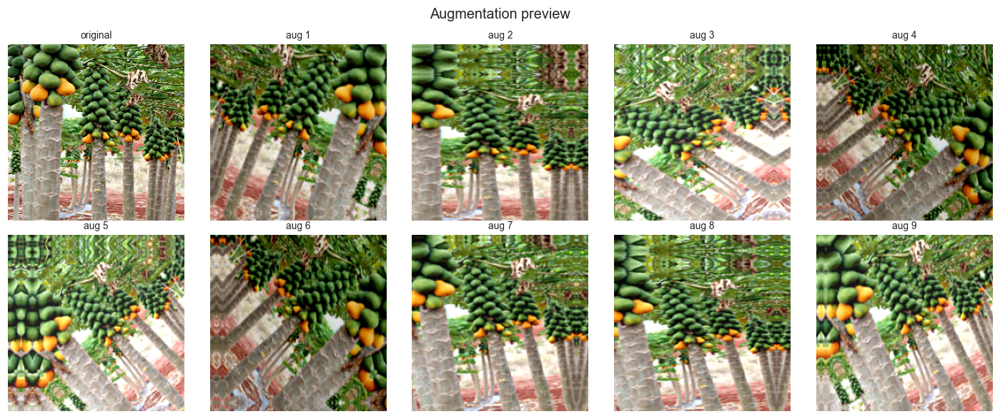

In [10]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.15, fill_mode="reflect", seed=SEED),
    layers.RandomZoom(0.20, 0.20, fill_mode="reflect", seed=SEED),
    layers.RandomTranslation(0.10, 0.10, fill_mode="reflect", seed=SEED),
    layers.RandomContrast(0.20, seed=SEED),
    layers.RandomBrightness(0.15, value_range=(0, 255), seed=SEED),
], name="augmentation")

# preview
img = xb[0:1]
fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
axes[0][0].imshow(img[0].numpy().astype("uint8")); axes[0][0].set_title("original", fontsize=9)
for i, ax in enumerate(axes.flatten()[1:]):
    aug = data_augmentation(img, training=True)[0].numpy()
    ax.imshow(np.clip(aug, 0, 255).astype("uint8")); ax.set_title(f"aug {i+1}", fontsize=9)
for ax in axes.flatten():
    ax.axis("off")
plt.suptitle("Augmentation preview", fontsize=13)
plt.tight_layout(); plt.savefig(ART / "augmentation_preview.png", bbox_inches="tight"); plt.show()

## 10. Class weights

Rare classes get a bigger loss contribution so the model does not just ignore them.

In [11]:
cw = compute_class_weight("balanced",
                          classes=np.arange(NUM_CLASSES),
                          y=train_df.label_id.values)
class_weights = {i: float(w) for i, w in enumerate(cw)}
print("weight range:", round(min(cw), 3), "-", round(max(cw), 3))

weight range: 0.74 - 1.321


## 11. The CNN model

Architecture, top to bottom:

```
Input 224x224x3 (raw 0-255)
  -> Augmentation           (train only)
  -> Rescaling to [-1, 1]   (baked in, so Flask needs zero preprocessing)
  -> MobileNetV2 conv backbone   <-- pure CNN: Conv2D, DepthwiseConv2D, BatchNorm, ReLU6
  -> Conv2D 256 (1x1) + BN + ReLU   <-- our own conv block on top
  -> GlobalAveragePooling2D
  -> Dropout 0.35 -> Dense 256 + L2 -> Dropout 0.35
  -> Dense 30 softmax
```

Every feature-extraction layer is convolutional. No transformers, no RNNs, no classical ML.

In [12]:
def build_model(num_classes, img_size=224, backbone_trainable=False):
    base = tf.keras.applications.MobileNetV2(
        input_shape=(img_size, img_size, 3),
        include_top=False, weights="imagenet")
    base.trainable = backbone_trainable

    inputs = layers.Input(shape=(img_size, img_size, 3), name="image")   # raw 0..255
    x = data_augmentation(inputs)
    x = layers.Rescaling(1. / 127.5, offset=-1.0, name="rescale")(x)
    x = base(x, training=False)

    x = layers.Conv2D(256, 1, padding="same", use_bias=False, name="head_conv")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Activation("relu", name="head_relu")(x)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.35, name="drop1")(x)
    x = layers.Dense(256, activation="relu",
                     kernel_regularizer=tf.keras.regularizers.l2(1e-4), name="fc1")(x)
    x = layers.Dropout(0.35, name="drop2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

    model = models.Model(inputs, outputs, name="CropVision_CNN")
    return model, base

model, base_model = build_model(NUM_CLASSES, IMG_SIZE, backbone_trainable=False)

model.compile(optimizer=tf.keras.optimizers.Adam(CFG["HEAD_LR"]),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy",
                       tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3")])

total = model.count_params()
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"total params    : {total:,}")
print(f"trainable params: {trainable:,}  ({trainable/total*100:.1f}%)")
model.summary()

total params    : 2,660,190
trainable params: 401,694  (15.1%)


Model: "CropVision_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_conv (Conv2D)              │ (None, 7, 7, 256)      │       327,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_bn (BatchNormalization)    │ (None, 7, 7, 256)      │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_relu (Activation)          │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 30)             │         7,710 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,660,190 (10.15 MB)

 Trainable params: 401,694 (1.53 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

## 12. Phase 1 - train the head (backbone frozen)

In [13]:
ckpt_path = str(ART / "best_phase1.keras")
cb_phase1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=4, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_accuracy",
                                       save_best_only=True, verbose=0),
]

hist1 = model.fit(train_ds,
                  validation_data=val_ds,
                  epochs=CFG["HEAD_EPOCHS"],
                  class_weight=class_weights,
                  callbacks=cb_phase1,
                  verbose=1)

print(f"\nPhase 1 best val_accuracy: {max(hist1.history['val_accuracy']):.4f}")

Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 273ms/step - accuracy: 0.1189 - loss: 3.3513 - top3: 0.2523 - val_accuracy: 0.3025 - val_loss: 2.8037 - val_top3: 0.4790 - learning_rate: 0.0010
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 218ms/step - accuracy: 0.2811 - loss: 2.7489 - top3: 0.5063 - val_accuracy: 0.4706 - val_loss: 2.1855 - val_top3: 0.6891 - learning_rate: 0.0010
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 226ms/step - accuracy: 0.4306 - loss: 2.2057 - top3: 0.6613 - val_accuracy: 0.5210 - val_loss: 1.7419 - val_top3: 0.7815 - learning_rate: 0.0010
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 225ms/step - accuracy: 0.4901 - loss: 1.9131 - top3: 0.7081 - val_accuracy: 0.5882 - val_loss: 1.5367 - val_top3: 0.8235 - learning_rate: 0.0010
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 224ms/step - accuracy: 0.5405 - loss: 1.6468 - top3: 0.7874 - val_accuracy: 0.6723 - val_loss: 1.3723 - val_top3: 0.8487 - learning_rate: 0.0010
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 229ms/step - accuracy: 0.6162

## 13. Phase 2 - fine-tune the top of the backbone

Unfreeze the deeper conv blocks and train with a much smaller learning rate.
BatchNorm layers stay frozen - with a batch size of 32 and a tiny dataset, updating the
running statistics is a reliable way to wreck a working model.

In [14]:
base_model.trainable = True
for layer in base_model.layers[:CFG["UNFREEZE_FROM"]]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(CFG["FINETUNE_LR"]),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy",
                       tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3")])

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"trainable params now: {trainable:,}")

cb_phase2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=12,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=5, min_lr=1e-7, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(str(ART / "best_finetuned.keras"),
                                       monitor="val_accuracy", save_best_only=True, verbose=0),
]

hist2 = model.fit(train_ds,
                  validation_data=val_ds,
                  epochs=CFG["FINETUNE_EPOCHS"],
                  initial_epoch=len(hist1.history["loss"]),
                  class_weight=class_weights,
                  callbacks=cb_phase2,
                  verbose=1)

print(f"\nPhase 2 best val_accuracy: {max(hist2.history['val_accuracy']):.4f}")

trainable params now: 2,241,310
Epoch 31/35
18/18 ━━━━━━━━━━━━━━━━━━━━ 11s 403ms/step - accuracy: 0.8955 - loss: 0.3777 - top3: 0.9838 - val_accuracy: 0.7227 - val_loss: 1.3069 - val_top3: 0.8487 - learning_rate: 5.0000e-05
Epoch 32/35
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 381ms/step - accuracy: 0.8973 - loss: 0.3805 - top3: 0.9838 - val_accuracy: 0.7647 - val_loss: 1.2004 - val_top3: 0.8571 - learning_rate: 5.0000e-05
Epoch 33/35
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 361ms/step - accuracy: 0.9099 - loss: 0.3231 - top3: 0.9892 - val_accuracy: 0.7311 - val_loss: 1.1791 - val_top3: 0.8739 - learning_rate: 5.0000e-05
Epoch 34/35
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 367ms/step - accuracy: 0.9225 - loss: 0.3033 - top3: 0.9946 - val_accuracy: 0.7563 - val_loss: 1.0930 - val_top3: 0.8824 - learning_rate: 5.0000e-05
Epoch 35/35
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 381ms/step - accuracy: 0.9333 - loss: 0.2756 - top3: 0.9928 - val_accuracy: 0.7731 - val_loss: 0.9543 - val_top3: 0.8655 - learning_rate: 5.0000e-05
Restoring mo

## 14. Training curves

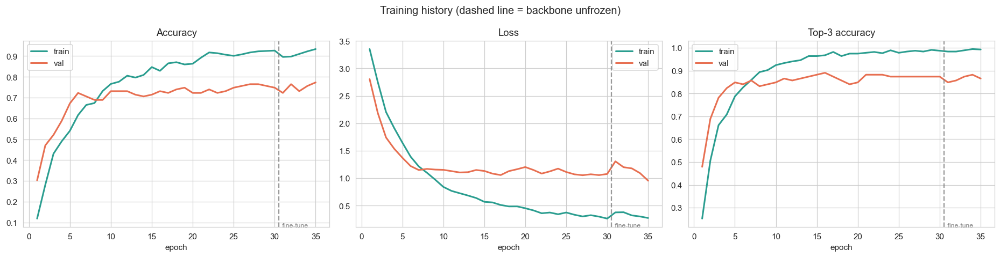

final train acc 0.9333 | val acc 0.7731 | gap 0.1602
Overfitting - raise dropout / augmentation.


In [15]:
def merge(h1, h2, key):
    return h1.history.get(key, []) + h2.history.get(key, [])

acc, vacc = merge(hist1, hist2, "accuracy"), merge(hist1, hist2, "val_accuracy")
loss, vloss = merge(hist1, hist2, "loss"), merge(hist1, hist2, "val_loss")
top3, vtop3 = merge(hist1, hist2, "top3"), merge(hist1, hist2, "val_top3")
switch = len(hist1.history["loss"])
ep = range(1, len(acc) + 1)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for a, (tr, va, name) in zip(ax, [(acc, vacc, "Accuracy"),
                                  (loss, vloss, "Loss"),
                                  (top3, vtop3, "Top-3 accuracy")]):
    a.plot(ep, tr, label="train", lw=2, color="#2a9d8f")
    a.plot(ep, va, label="val", lw=2, color="#e76f51")
    a.axvline(switch + 0.5, ls="--", c="gray", alpha=0.8)
    a.text(switch + 0.7, a.get_ylim()[0], " fine-tune", fontsize=8, color="gray")
    a.set_title(name); a.set_xlabel("epoch"); a.legend()
plt.suptitle("Training history (dashed line = backbone unfrozen)", fontsize=13)
plt.tight_layout(); plt.savefig(ART / "training_curves.png", bbox_inches="tight"); plt.show()

gap = acc[-1] - vacc[-1]
print(f"final train acc {acc[-1]:.4f} | val acc {vacc[-1]:.4f} | gap {gap:.4f}")
print("Overfitting - raise dropout / augmentation." if gap > 0.15 else "Generalization gap looks healthy.")

## 15. Test-set evaluation

First and only time the test set is used.

In [16]:
test_metrics = model.evaluate(test_ds, verbose=0)
print("TEST RESULTS")
for name, val in zip(model.metrics_names, test_metrics):
    print(f"  {name:10s}: {val:.4f}")

y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)
y_true = np.concatenate([y.numpy() for _, y in test_ds])

print("\n" + classification_report(y_true, y_pred,
                                   labels=np.arange(NUM_CLASSES),
                                   target_names=DISPLAY, digits=3, zero_division=0))

TEST RESULTS
  loss      : 1.1946
  compile_metrics: 0.7059

                     precision    recall  f1-score   support

             Cherry      0.750     0.600     0.667         5
       Coffee Plant      0.500     0.250     0.333         4
           Cucumber      1.000     1.000     1.000         4
   Fox Nut(makhana)      0.800     1.000     0.889         4
              Lemon      1.000     0.750     0.857         4
         Olive Tree      1.000     0.250     0.400         4
Pearl Millet(bajra)      0.800     0.800     0.800         5
      Tobacco Plant      0.556     1.000     0.714         5
             Almond      1.000     0.333     0.500         3
             Banana      0.400     1.000     0.571         4
           Cardamom      1.000     1.000     1.000         4
             Chilli      0.000     0.000     0.000         4
              Clove      1.000     0.250     0.400         4
            Coconut      1.000     0.750     0.857         4
             Cotton    

2026-09-07 18:47:29.548335: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 16. Confusion matrix

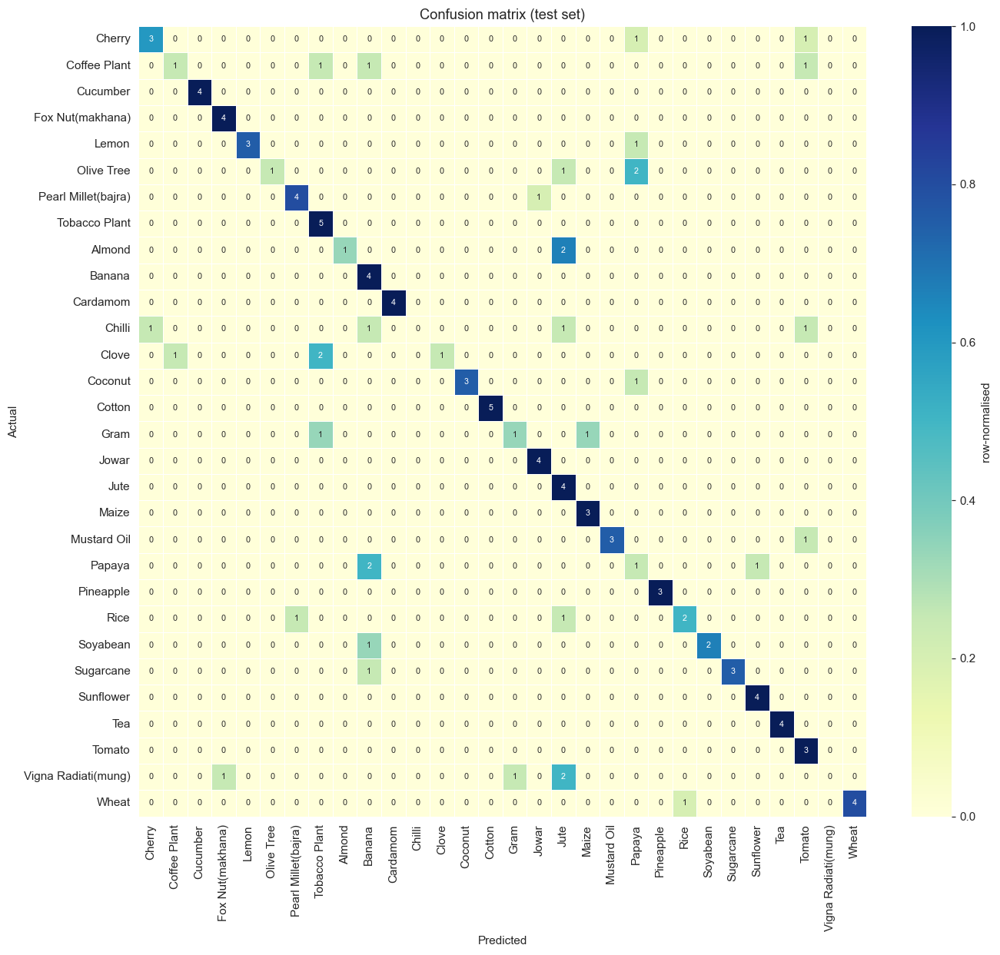

Most confused pairs (actual -> predicted):
  2x   Olive Tree  ->  Papaya
  2x   Almond  ->  Jute
  2x   Clove  ->  Tobacco Plant
  2x   Papaya  ->  Banana
  2x   Vigna Radiati(mung)  ->  Jute
  1x   Cherry  ->  Papaya
  1x   Cherry  ->  Tomato
  1x   Coffee Plant  ->  Tobacco Plant
  1x   Coffee Plant  ->  Banana
  1x   Coffee Plant  ->  Tomato


In [17]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(max(10, NUM_CLASSES * 0.42), max(8, NUM_CLASSES * 0.38)))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="YlGnBu", cbar_kws={"label": "row-normalised"},
            xticklabels=DISPLAY, yticklabels=DISPLAY, linewidths=0.4,
            linecolor="white", annot_kws={"size": 7}, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion matrix (test set)")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout(); plt.savefig(ART / "confusion_matrix.png", bbox_inches="tight"); plt.show()

# most confused class pairs
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(DISPLAY[i], DISPLAY[j], off[i, j])
         for i, j in zip(*np.nonzero(off))]
pairs.sort(key=lambda t: -t[2])
print("Most confused pairs (actual -> predicted):")
for a, b, c in pairs[:10]:
    print(f"  {c}x   {a}  ->  {b}")

## 17. Per-class accuracy

Anything under ~0.6 is a class you should collect more images for. Mention this in your
project report as the "future work" section.

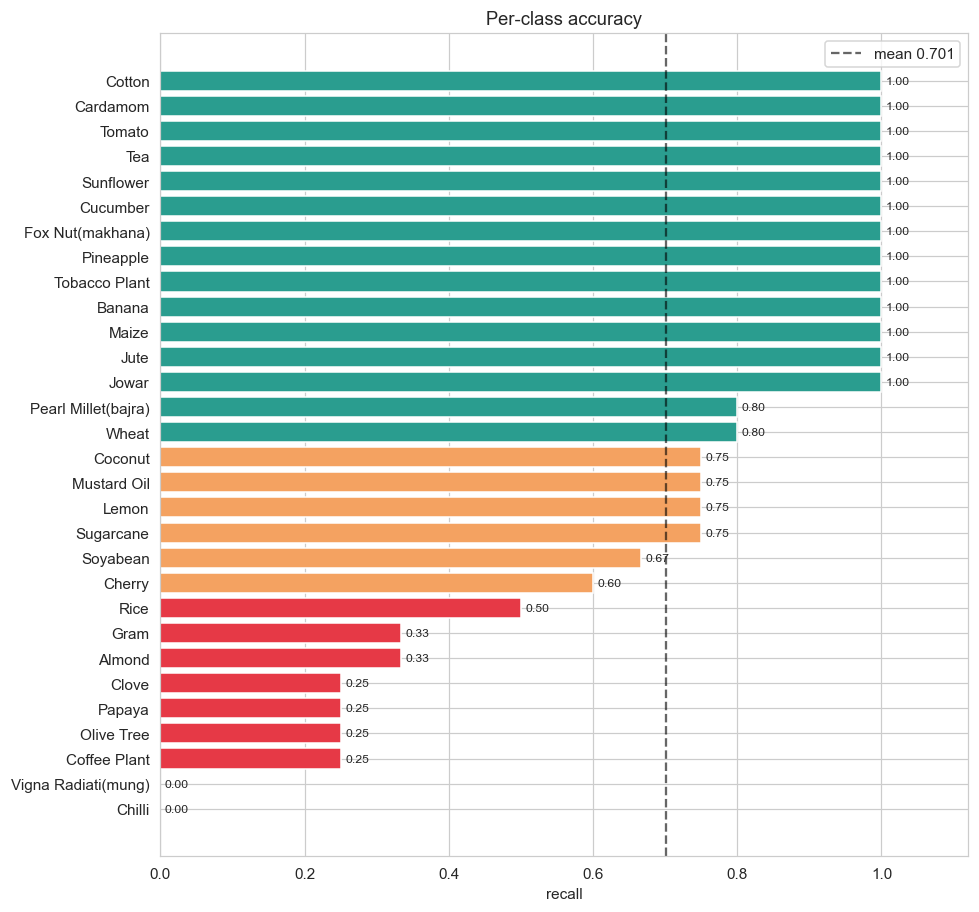

Weak classes: ['Chilli', 'Vigna Radiati(mung)', 'Coffee Plant', 'Olive Tree', 'Papaya', 'Clove', 'Almond', 'Gram', 'Rice']


In [18]:
per_class = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
order = np.argsort(per_class)
colors = ["#e63946" if v < 0.6 else "#f4a261" if v < 0.8 else "#2a9d8f" for v in per_class[order]]

fig, ax = plt.subplots(figsize=(9, max(6, NUM_CLASSES * 0.28)))
bars = ax.barh([DISPLAY[i] for i in order], per_class[order], color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.axvline(per_class.mean(), ls="--", c="black", alpha=0.6,
           label=f"mean {per_class.mean():.3f}")
ax.set_xlim(0, 1.12); ax.set_xlabel("recall"); ax.set_title("Per-class accuracy"); ax.legend()
plt.tight_layout(); plt.savefig(ART / "per_class_accuracy.png", bbox_inches="tight"); plt.show()

weak = [DISPLAY[i] for i in order if per_class[i] < 0.6]
print("Weak classes:", weak if weak else "none - all above 0.6")

## 18. Error gallery

Looking at what it gets wrong is usually more informative than the accuracy number.

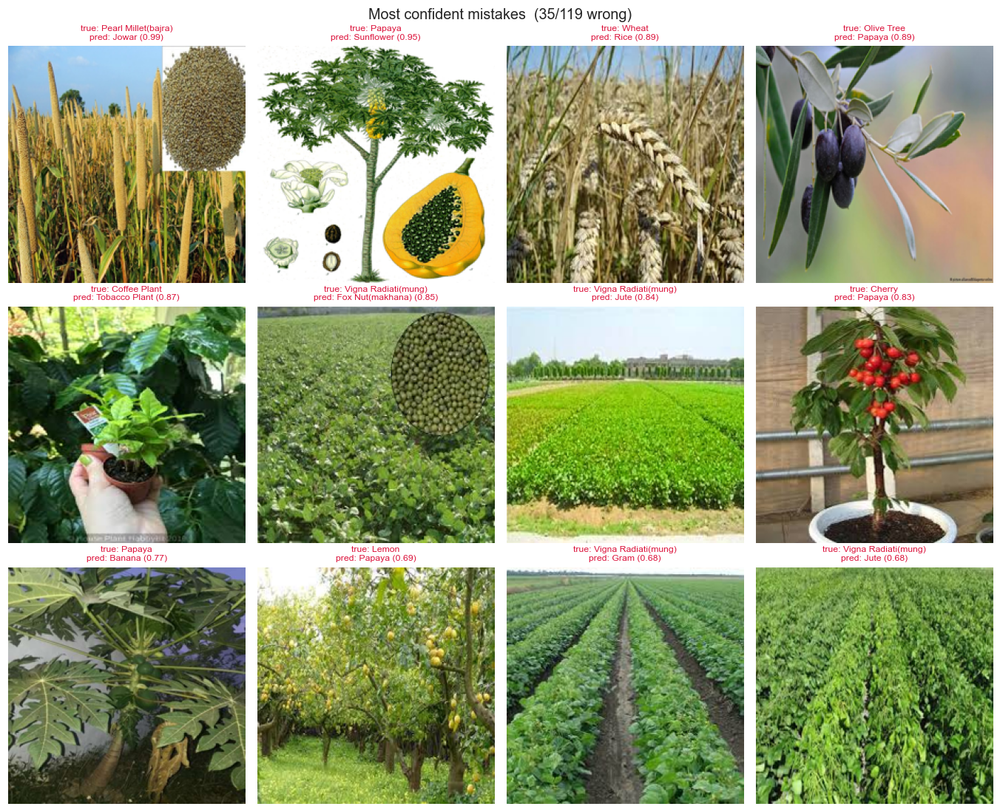

In [19]:
test_paths = test_df.filepath.values
conf = y_prob.max(axis=1)
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-conf[wrong])]          # most confident mistakes first

if len(wrong) == 0:
    print("Zero misclassifications on the test set.")
else:
    show = wrong[:12]
    ncol = 4; nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 3.1, nrow * 3.4))
    for ax, idx in zip(np.atleast_1d(axes).flatten(), show):
        with Image.open(test_paths[idx]) as im:
            ax.imshow(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        ax.set_title(f"true: {DISPLAY[y_true[idx]]}\npred: {DISPLAY[y_pred[idx]]} ({conf[idx]:.2f})",
                     fontsize=8, color="crimson")
        ax.axis("off")
    for ax in np.atleast_1d(axes).flatten()[len(show):]:
        ax.axis("off")
    plt.suptitle(f"Most confident mistakes  ({len(wrong)}/{len(y_true)} wrong)", fontsize=13)
    plt.tight_layout(); plt.savefig(ART / "error_gallery.png", bbox_inches="tight"); plt.show()

## 19. Grad-CAM

Shows which pixels drove the prediction. Two reasons to keep this:
it proves the CNN is looking at the crop and not the background, and it makes a genuinely
good screenshot for the project listing and demo video.

pre : ['augmentation', 'rescale']
head: ['head_conv', 'head_bn', 'head_relu', 'gap', 'drop1', 'fc1', 'drop2', 'predictions']


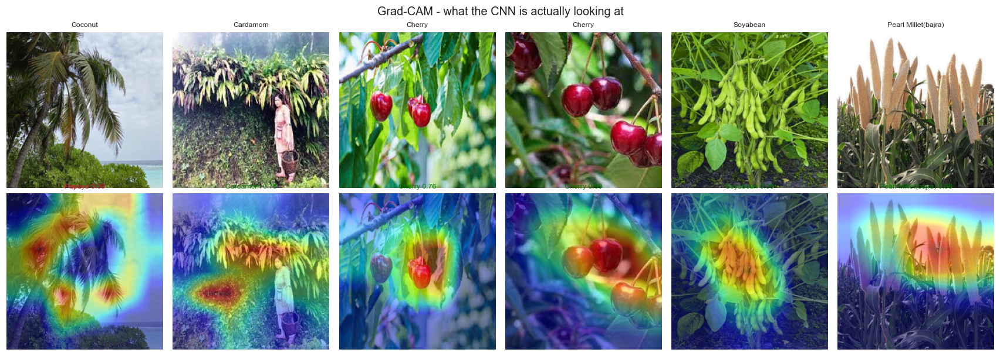

In [21]:
LAST_CONV = "out_relu"   # final conv activation inside MobileNetV2

# 1) conv feature extractor -- built INSIDE the base model's own graph (safe)
feature_extractor = models.Model(base_model.input,
                                 base_model.get_layer(LAST_CONV).output,
                                 name="feature_extractor")

# 2) split the outer model around the backbone (no hardcoded names)
base_pos    = [i for i, l in enumerate(model.layers) if l is base_model][0]
pre_layers  = model.layers[1:base_pos]      # augmentation + rescale
head_layers = model.layers[base_pos + 1:]   # head_conv ... predictions

print("pre :", [l.name for l in pre_layers])
print("head:", [l.name for l in head_layers])


def grad_cam(img_batch, class_idx=None):
    x = tf.convert_to_tensor(img_batch, dtype=tf.float32)   # raw 0..255
    for lyr in pre_layers:                                  # augmentation is identity here
        x = lyr(x, training=False)

    with tf.GradientTape() as tape:
        conv_out = feature_extractor(x, training=False)
        tape.watch(conv_out)                                # intermediate tensor -> must watch
        h = conv_out
        for lyr in head_layers:
            h = lyr(h, training=False)
        idx = tf.argmax(h[0]) if class_idx is None else tf.constant(class_idx, tf.int64)
        score = h[:, idx]

    grads = tape.gradient(score, conv_out)
    if grads is None:
        raise RuntimeError("No gradient reached the conv layer -- check LAST_CONV name.")

    weights = tf.reduce_mean(grads, axis=(1, 2))            # global-average-pool the gradients
    cam = tf.reduce_sum(conv_out[0] * weights[0], axis=-1)
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), int(idx), float(h[0][idx])


picks = np.random.RandomState(SEED).choice(len(test_df), size=min(6, len(test_df)), replace=False)
fig, axes = plt.subplots(2, len(picks), figsize=(len(picks) * 2.6, 5.6))
for col, i in enumerate(picks):
    p = test_paths[i]
    with Image.open(p) as im:
        pil = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.asarray(pil, dtype="float32")[None, ...]
    cam, idx, prob = grad_cam(arr)
    heat = np.array(Image.fromarray(np.uint8(cam * 255)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))

    axes[0][col].imshow(pil); axes[0][col].set_title(DISPLAY[y_true[i]], fontsize=8)
    axes[1][col].imshow(pil); axes[1][col].imshow(heat, cmap="jet", alpha=0.45)
    ok = idx == y_true[i]
    axes[1][col].set_title(f"{DISPLAY[idx]} {prob:.2f}", fontsize=8,
                           color="green" if ok else "crimson")
    axes[0][col].axis("off"); axes[1][col].axis("off")
plt.suptitle("Grad-CAM - what the CNN is actually looking at", fontsize=13)
plt.tight_layout(); plt.savefig(ART / "gradcam.png", bbox_inches="tight"); plt.show()

## 20. Optional - from-scratch CNN baseline

This is the "pure CNN, no pretrained weights" version. Train it, note the accuracy, and
put both numbers side by side in your report. It is the single easiest way to justify the
transfer-learning choice to an examiner.

Set `CFG["TRAIN_SCRATCH_BASELINE"] = False` to skip.

Epoch 1/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.0396 - loss: 3.7417 - val_accuracy: 0.0420 - val_loss: 3.4275
Epoch 2/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.0613 - loss: 3.4213 - val_accuracy: 0.0252 - val_loss: 3.4846
Epoch 3/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 52s 3s/step - accuracy: 0.0757 - loss: 3.3666 - val_accuracy: 0.0252 - val_loss: 3.4772
Epoch 4/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 70s 4s/step - accuracy: 0.0955 - loss: 3.2377 - val_accuracy: 0.0336 - val_loss: 3.4261
Epoch 5/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 68s 4s/step - accuracy: 0.0865 - loss: 3.2268 - val_accuracy: 0.0252 - val_loss: 3.6052
Epoch 6/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - accuracy: 0.1117 - loss: 3.1449 - val_accuracy: 0.0168 - val_loss: 3.8799
Epoch 7/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 68s 4s/step - accuracy: 0.0955 - loss: 3.1385 - val_accuracy: 0.0084 - val_loss: 4.4066
Epoch 8/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 67s 4s/step - accuracy: 0.1532 - loss: 3.0308 - val_accuracy: 0.0252 - val_loss:

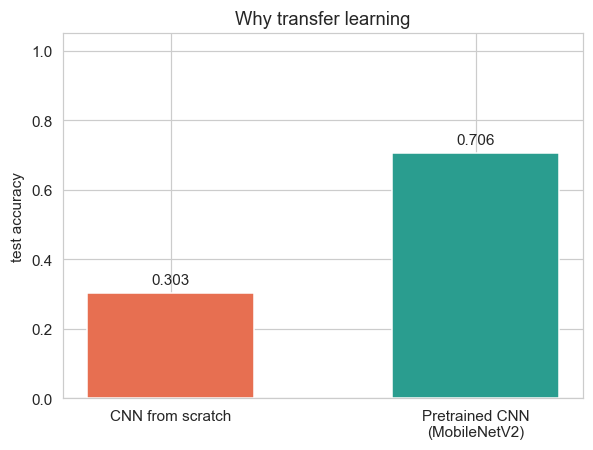

scratch  : 0.3025
transfer : 0.7059   (+40.3 points)


In [22]:
if CFG["TRAIN_SCRATCH_BASELINE"]:
    def build_scratch_cnn(num_classes, img_size=224):
        inp = layers.Input((img_size, img_size, 3))
        x = data_augmentation(inp)
        x = layers.Rescaling(1. / 255.)(x)
        for filters in [32, 64, 128, 256]:
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
            x = layers.MaxPooling2D(2)(x)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.4)(x)
        x = layers.Dense(256, activation="relu")(x)
        x = layers.Dropout(0.4)(x)
        out = layers.Dense(num_classes, activation="softmax")(x)
        return models.Model(inp, out, name="Scratch_CNN")

    scratch = build_scratch_cnn(NUM_CLASSES, IMG_SIZE)
    scratch.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                    loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    hs = scratch.fit(train_ds, validation_data=val_ds, epochs=40,
                     class_weight=class_weights, verbose=1,
                     callbacks=[tf.keras.callbacks.EarlyStopping(
                         monitor="val_accuracy", patience=12, restore_best_weights=True)])

    scratch_test = scratch.evaluate(test_ds, verbose=0)[1]
    transfer_test = float(test_metrics[1])

    fig, ax = plt.subplots(figsize=(5.5, 4.2))
    bars = ax.bar(["CNN from scratch", "Pretrained CNN\n(MobileNetV2)"],
                  [scratch_test, transfer_test], color=["#e76f51", "#2a9d8f"], width=0.55)
    ax.bar_label(bars, fmt="%.3f", padding=4)
    ax.set_ylim(0, 1.05); ax.set_ylabel("test accuracy"); ax.set_title("Why transfer learning")
    plt.tight_layout(); plt.savefig(ART / "scratch_vs_transfer.png", bbox_inches="tight"); plt.show()

    print(f"scratch  : {scratch_test:.4f}")
    print(f"transfer : {transfer_test:.4f}   (+{(transfer_test-scratch_test)*100:.1f} points)")
    baseline_result = {"scratch_test_acc": float(scratch_test),
                       "transfer_test_acc": transfer_test}
else:
    baseline_result = None
    print("Skipped.")

## 21. Save everything Flask needs

Written into `artifacts/`:

| file | used for |
|---|---|
| `crop_cnn_model.keras` | the model Flask loads |
| `labels.json` | class order, display names, image size, confidence threshold |
| `metrics.json` | numbers for the "model info" page |
| `crop_cnn_model.tflite` | optional lightweight build for a low-RAM VPS |
| `*.png` | charts for your listing / report |

In [24]:
MODEL_PATH = ART / "crop_cnn_model.keras"
model.save(MODEL_PATH)
print("saved:", MODEL_PATH, f"({MODEL_PATH.stat().st_size/1e6:.1f} MB)")

labels_payload = {
    "classes": CLASSES,
    "display_names": DISPLAY,
    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "input_range": "0-255 float32 (rescaling is inside the model)",
    "confidence_threshold": 0.45,
    "model_file": MODEL_PATH.name,
}
(ART / "labels.json").write_text(json.dumps(labels_payload, indent=2))

metrics_payload = {
    "architecture": "MobileNetV2 CNN backbone + custom conv/dense head",
    "test_accuracy": float(test_metrics[1]),
    "test_top3_accuracy": float(test_metrics[2]),
    "test_loss": float(test_metrics[0]),
    "best_val_accuracy": float(max(vacc)),
    "epochs_trained": len(acc),
    "total_params": int(total),
    "dataset": {
        "total_images": int(len(df)),
        "train": int(len(train_df)),
        "val": int(len(val_df)),
        "test": int(len(test_df)),
        "classes": NUM_CLASSES,
    },
    "per_class_recall": {DISPLAY[i]: round(float(per_class[i]), 4) for i in range(NUM_CLASSES)},
    "scratch_baseline": baseline_result,
}
(ART / "metrics.json").write_text(json.dumps(metrics_payload, indent=2))
print("saved: labels.json, metrics.json")

saved: artifacts/crop_cnn_model.keras (29.2 MB)
saved: labels.json, metrics.json


In [25]:
# optional: TFLite build - roughly 4x smaller, good if your Hostinger VPS is RAM-tight
try:
    conv = tf.lite.TFLiteConverter.from_keras_model(model)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = conv.convert()
    p = ART / "crop_cnn_model.tflite"
    p.write_bytes(tflite_model)
    print(f"saved: {p} ({len(tflite_model)/1e6:.1f} MB)")
except Exception as e:
    print("TFLite export skipped:", str(e)[:120])

INFO:tensorflow:Assets written to: /var/folders/lb/9scg08m91mg1tsc8skvy9mm80000gn/T/tmpvbywu336/assets


INFO:tensorflow:Assets written to: /var/folders/lb/9scg08m91mg1tsc8skvy9mm80000gn/T/tmpvbywu336/assets


Saved artifact at '/var/folders/lb/9scg08m91mg1tsc8skvy9mm80000gn/T/tmpvbywu336'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 30), dtype=tf.float32, name=None)
Captures:
  6255202320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6070555520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6068780752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6068771072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6070563792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6070351856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6070101696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6070095712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6070107152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6070093072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6070097648: TensorSpec(sha

W0000 00:00:1788790092.869308 1160087 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1788790092.869435 1160087 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2026-09-07 19:38:12.871240: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/lb/9scg08m91mg1tsc8skvy9mm80000gn/T/tmpvbywu336
2026-09-07 19:38:12.876781: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-09-07 19:38:12.876788: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/lb/9scg08m91mg1tsc8skvy9mm80000gn/T/tmpvbywu336
I0000 00:00:1788790092.935862 1160087 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
2026-09-07 19:38:12.946697: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-09-07 19:38:13.323270: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folder

## 22. Inference sanity check

This is exactly the function that goes into the Flask app. If this cell prints sensible
output, the Flask integration cannot fail on a preprocessing mismatch.

In [26]:
loaded = tf.keras.models.load_model(MODEL_PATH)
meta = json.loads((ART / "labels.json").read_text())

def predict_crop(image_path, model=loaded, meta=meta, top_k=3):
    size = meta["img_size"]
    with Image.open(image_path) as im:
        im = im.convert("RGB").resize((size, size))
        arr = np.asarray(im, dtype="float32")[None, ...]      # 0..255, no other prep
    probs = model.predict(arr, verbose=0)[0]
    idx = probs.argsort()[::-1][:top_k]
    top = [{"class": meta["classes"][i],
            "label": meta["display_names"][i],
            "confidence": round(float(probs[i]), 4)} for i in idx]
    best = top[0]
    return {
        "prediction": best["label"],
        "confidence": best["confidence"],
        "is_confident": best["confidence"] >= meta["confidence_threshold"],
        "top_k": top,
    }

for p in test_df.sample(3, random_state=SEED).filepath:
    out = predict_crop(p)
    print(Path(p).parent.name, "->", out["prediction"],
          f"{out['confidence']:.3f}", "| top3:",
          [f"{t['label']} {t['confidence']:.2f}" for t in out["top_k"]])

coconut -> Papaya 0.390 | top3: ['Papaya 0.39', 'Banana 0.16', 'Jute 0.15']
cardamom -> Cardamom 0.775 | top3: ['Cardamom 0.78', 'Coffee Plant 0.06', 'Olive Tree 0.05']
Cherry -> Cherry 0.764 | top3: ['Cherry 0.76', 'Clove 0.11', 'Coffee Plant 0.05']


## 23. Done

`artifacts/` now contains the model, labels, metrics and all charts.

Next step is the Flask app - upload page, prediction endpoint, confidence handling,
Grad-CAM overlay in the browser, and a model-info page that reads `metrics.json`.

Quick fixes if the numbers disappoint:

- **Val accuracy stuck below 70%** - bump `HEAD_EPOCHS`, or set `UNFREEZE_FROM` to 60 to fine-tune more of the backbone
- **Big train/val gap** - raise dropout to 0.5, strengthen `RandomZoom` / `RandomRotation`
- **One or two classes always wrong** - check the folder, this dataset has a few mislabelled images
- **OOM on CPU** - drop `BATCH_SIZE` to 16